<a href="https://colab.research.google.com/github/Aldyth11/PCVK_Ganjil_2026/blob/main/Week07_09.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. TUGAS PRAKTIKUM

## D1. Tugas Individu

### NO 3

In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

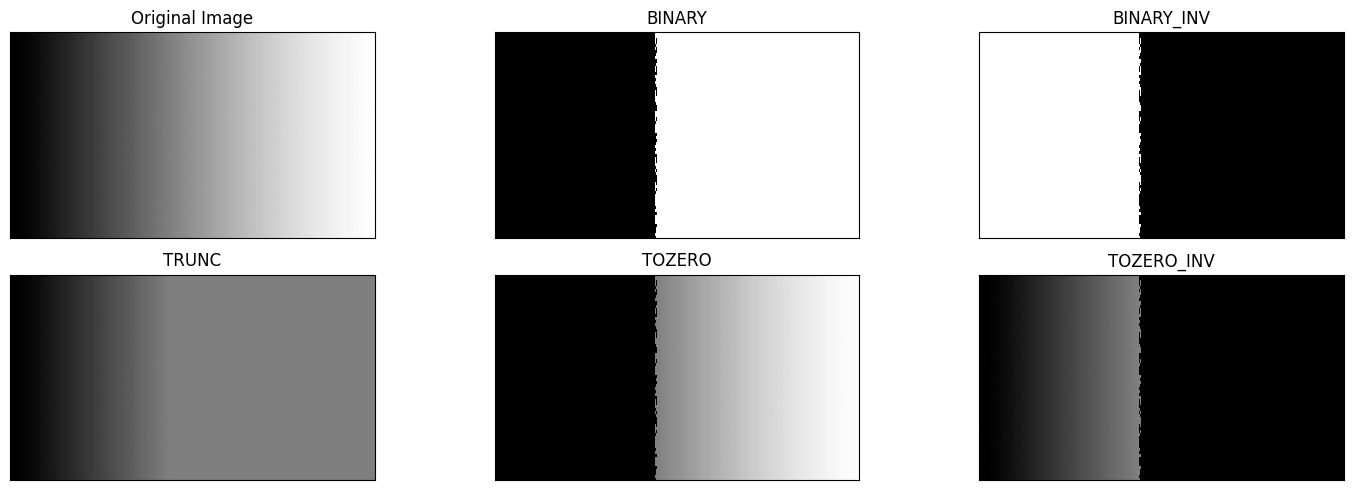

In [ ]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

# Path gambar disesuaikan dengan folder kamu
filename = '/content/drive/MyDrive/PCVK2026/gradient.jpg'
img = cv.imread(filename)

thresh = 127 # nilai Threshold yang ditentukan
maxval = 255

# 1. threshold binary jika pixel di img>127, maka thresh1 bernilai 255(putih), selain itu bernilai 0(hitam)
ret, thresh1 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY)

# 2. threshold binary inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai maxval
ret, thresh2 = cv.threshold(img, thresh, maxval, cv.THRESH_BINARY_INV)

# 3. Threshold Truncate jika pixel>thresh, maka pixel bernilai thresh; selain itu akan bernilai tetap
ret, thresh3 = cv.threshold(img, thresh, maxval, cv.THRESH_TRUNC)

# 4. Threshold Tozero jika pixel>thresh, maka pixel bernilai tetap; selain itu akan bernilai 0
ret, thresh4 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO)

# 5. Threshold Tozero Inverse jika pixel>thresh, maka pixel bernilai 0; selain itu akan bernilai tetap
ret, thresh5 = cv.threshold(img, thresh, maxval, cv.THRESH_TOZERO_INV)

titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, thresh1, thresh2, thresh3, thresh4, thresh5]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

### NO 4

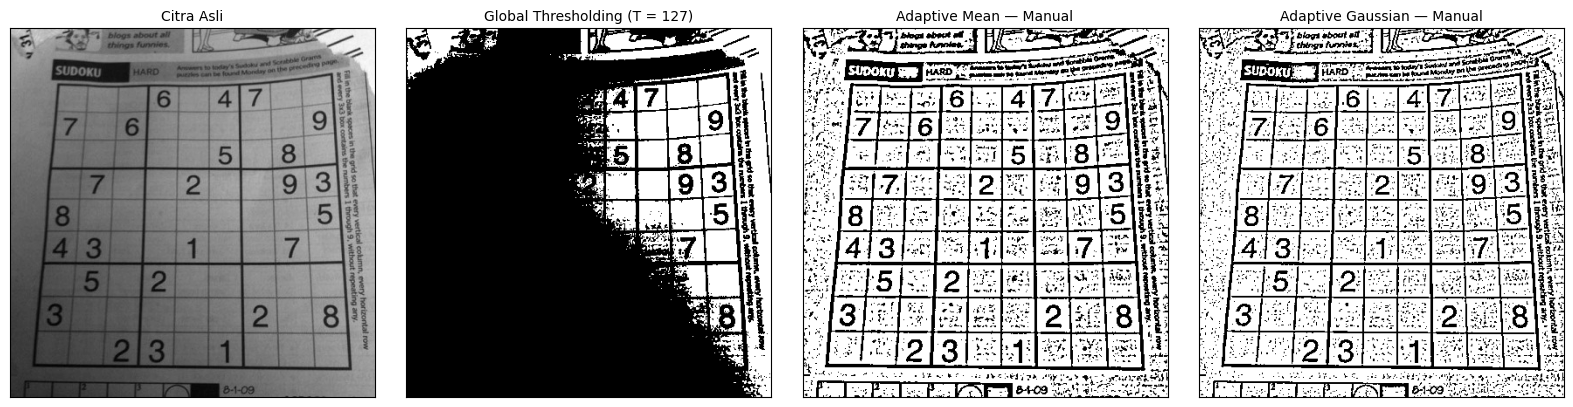

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# 1. Load citra dalam bentuk grayscale
img_path = '/content/drive/MyDrive/PCVK2026/sudoku-original.jpg'
img = cv.imread(img_path, cv.IMREAD_GRAYSCALE)

if img is None:
    raise ValueError(f"Gambar tidak ditemukan di path: {img_path}")

# Parameter Soal
T_global = 127
block_size = 11  # Ukuran jendela 11x11
C = 2
sigma = 2
pad = block_size // 2

# A. Global Thresholding Manual (T = 127)
global_thresh = np.where(img > T_global, 255, 0).astype(np.uint8)

# B. Adaptive Mean Manual
# Padding citra agar area pinggir tetap bisa diproses
padded_img = np.pad(img, pad_width=pad, mode='reflect')
h, w = img.shape

# Menghitung mean lokal secara manual untuk setiap piksel
mean_local = np.zeros((h, w), dtype=np.float32)

for i in range(h):
    for j in range(w):
        # Ambil region/jendela ukuran 11x11
        window = padded_img[i:i + block_size, j:j + block_size]
        mean_local[i, j] = np.mean(window)

# Nilai ambang tiap piksel: T(x, y) = Mean_lokal - C
adaptive_mean = np.where(img > (mean_local - C), 255, 0).astype(np.uint8)

# C. Adaptive Gaussian Manual
# 1. Buat Kernel Gaussian 2D manual
x, y = np.mgrid[-pad:pad+1, -pad:pad+1]
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))
gaussian_kernel /= gaussian_kernel.sum()  # Normalisasi kernel

# 2. Konvolusi Manual dengan Kernel Gaussian
gaussian_local = np.zeros((h, w), dtype=np.float32)

for i in range(h):
    for j in range(w):
        window = padded_img[i:i + block_size, j:j + block_size]
        # Perkalian elemen per elemen dengan kernel Gaussian
        gaussian_local[i, j] = np.sum(window * gaussian_kernel)

# Nilai ambang tiap piksel: T(x, y) = Gaussian_lokal - C
adaptive_gaussian = np.where(img > (gaussian_local - C), 255, 0).astype(np.uint8)

# D. Visualisasi Hasil
titles = [
    'Citra Asli',
    'Global Thresholding (T = 127)',
    'Adaptive Mean — Manual',
    'Adaptive Gaussian — Manual'
]
images = [img, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(16, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i], fontsize=10)
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

### NO 5

In [ ]:
input_path = '/content/drive/MyDrive/PCVK2026/lena.jpg'
output_path = '/content/drive/MyDrive/PCVK2026/lena_gs_lc2.jpg'

img_gray = cv.imread(input_path, cv.IMREAD_GRAYSCALE)

if img_gray is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan di: {input_path}")

img_lc = cv.convertScaleAbs(img_gray, alpha=0.5, beta=0)

cv.imwrite(output_path, img_lc)

True

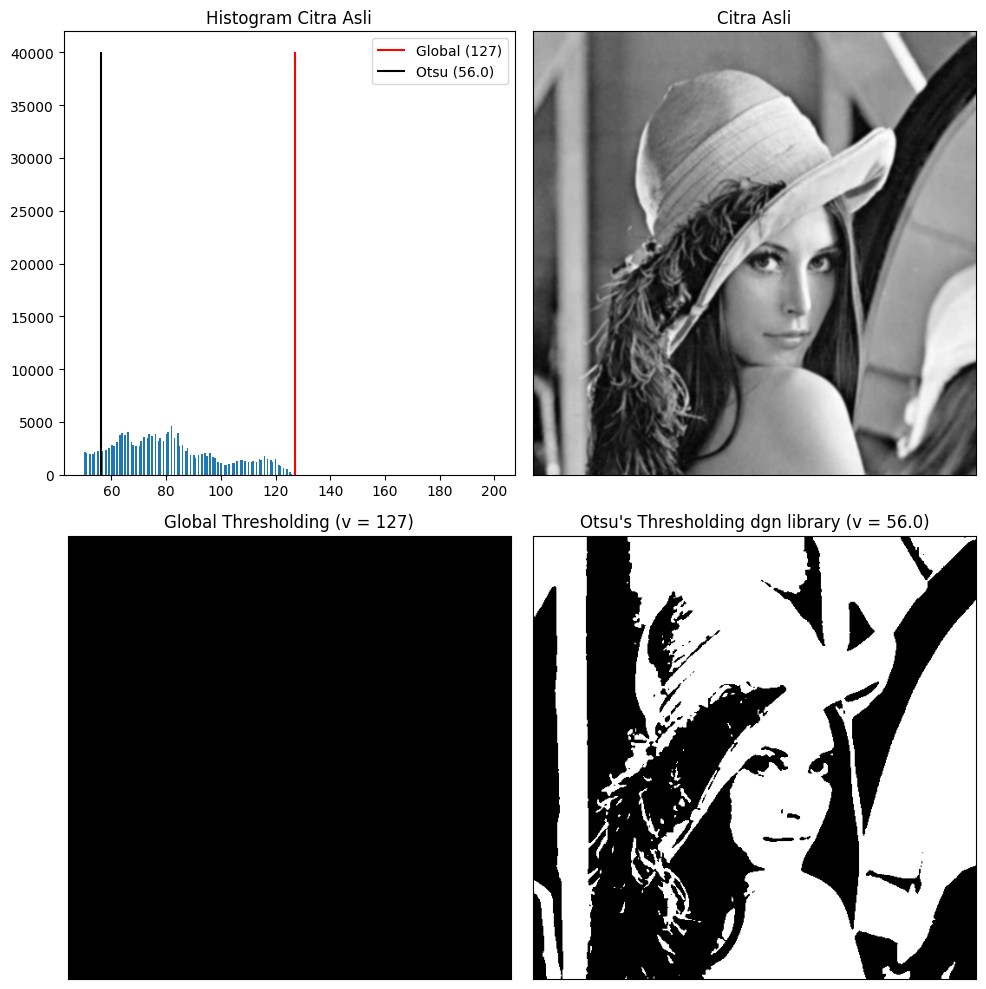

In [ ]:
filename = '/content/drive/MyDrive/PCVK2026/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)
ret2, th2 = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)

x = "Otsu's Thresholding dgn library (v = " + str(ret2) + ")"
titles = ['Citra Asli', 'Global Thresholding (v = 127)', x]
citra3 = [blur, th1, th2]

plt.figure(figsize=(10, 10))

# Subplot 1: Histogram Citra Asli
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, range=(50, 200))
plt.vlines(ret, 0, 40000, colors='red', label='Global (127)')  # garis vertikal merah menunjukan threshold global 127
plt.vlines(ret2, 0, 40000, colors='black', label=f'Otsu ({ret2})') # garis vertikal hitam menunjukkan threshold hasil otsu's
plt.title('Histogram Citra Asli')
plt.legend()

# Subplot 2, 3, 4: Tampilan Citra
for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

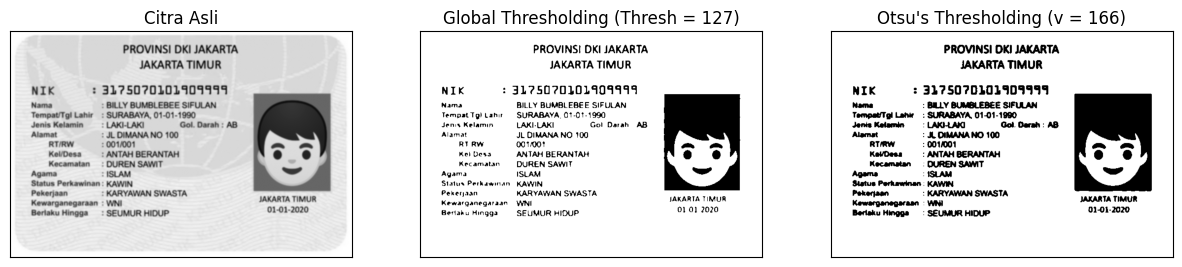

In [ ]:
path_ktp = '/content/drive/MyDrive/PCVK2026/ktp_fulan.jpg'
img_ktp = cv.imread(path_ktp, 0)
blur_ktp = cv.GaussianBlur(img_ktp, (5, 5), 0)

otsu_biner_ktp, otsu_thresh_ktp = otsu(blur_ktp)
ret, th1_ktp = cv.threshold(blur_ktp, thresh_global, 255, cv.THRESH_BINARY)

titles_ktp = [
    'Citra Asli',
    f'Global Thresholding (Thresh = {thresh_global})',
    f'Otsu\'s Thresholding (v = {otsu_thresh_ktp})'
]
citra_ktp = [blur_ktp, th1_ktp, otsu_biner_ktp]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(citra_ktp[i], cmap='gray')
    plt.title(titles_ktp[i])
    plt.xticks([]), plt.yticks([])
plt.show()

Pertanyaan:
Mengapa hasil tampilan Binary Thresholding semua bernilai 0 atau hitam semua? Jelaskan alasannya dalam bentuk histogram dan berapa angka ambang batas (Thresh) supaya gambar Lena ini masih terlihat?

Jawaban Analisis:

1. Penyebab Hasil Thresholding
Pada gambar Lena yang digunakan, rentang nilai intensitas piksel berada pada kisaran 100 sampai 160. Jika dilakukan Global Thresholding dengan nilai ambang batas 127, piksel yang nilainya di bawah atau sama dengan 127 akan diubah menjadi 0 atau hitam, sedangkan piksel di atas 127 diubah menjadi 255 atau putih. Karena sebagian besar piksel pada gambar berkumpul di bawah 127, hasil thresholding didominasi oleh warna hitam.

2. Penjelasan Berdasarkan Histogram
Berdasarkan bentuk histogram, distribusi nilai piksel gambar Lena berpusat di area tengah yaitu antara 100 hingga 160. Garis ambang batas global T = 127 memotong tepat di tengah puncak histogram tersebut. Hal ini menyebabkan area yang intensitasnya lebih rendah dari 127 terpotong menjadi hitam, sehingga detail gambar hilang.

3. Angka Ambang Batas Ideal
Supaya detail gambar Lena tetap terlihat dengan jelas dan seimbang antara latar depan serta latar belakang, nilai ambang batas ideal yang didapatkan melalui perhitungan otomatis metode Otsu adalah v = 125. Dengan threshold 125, pemisahan antara objek dan background menjadi optimal sesuai sebaran histogramnya.

### NO 6

Seed (baris, kolom): (36, 43) | intensitas: 159


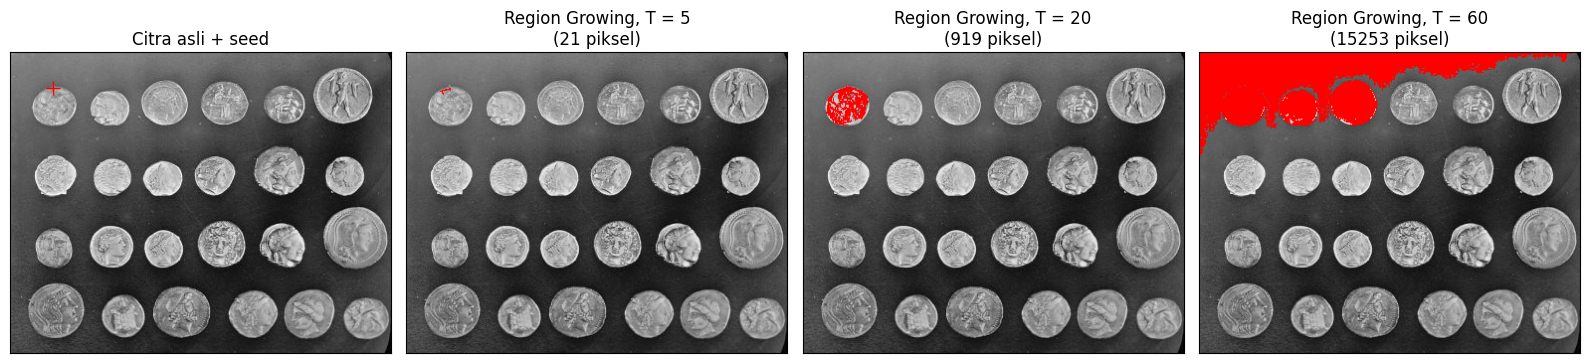

In [ ]:
from skimage import data

# Load citra coins dan ubah ke uint8 (0-255)
gray = data.coins().astype(np.uint8)

# Titik seed dalam koin
seed = (36, 43)
seed_val = gray[seed]
tolerances = [5, 20, 60]

# Fungsi Region Growing Manual
def region_growing_manual(img, seed, tolerance):
    h, w = img.shape
    visited = np.zeros((h, w), dtype=bool)
    mask = np.zeros((h, w), dtype=bool)

    seed_val = int(img[seed])
    queue = [seed]
    visited[seed] = True

    neighbors = [(-1, 0), (1, 0), (0, -1), (0, 1)]

    while queue:
        r, c = queue.pop(0)
        mask[r, c] = True

        for dr, dc in neighbors:
            nr, nc = r + dr, c + dc
            if 0 <= nr < h and 0 <= nc < w and not visited[nr, nc]:
                if abs(int(img[nr, nc]) - seed_val) <= tolerance:
                    visited[nr, nc] = True
                    queue.append((nr, nc))

    return mask

print(f"Seed (baris, kolom): {seed} | intensitas: {seed_val}")

plt.figure(figsize=(16, 4))

# 1. Citra Asli + Seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.xticks([]), plt.yticks([])

# 2. Hasil Region Growing T=5, T=20, T=60
for i, T in enumerate(tolerances):
    mask = region_growing_manual(gray, seed, T)
    pixel_count = np.sum(mask)

    overlay = np.stack([gray]*3, axis=-1)
    overlay[mask] = [255, 0, 0]

    plt.subplot(1, 4, i + 2)
    plt.imshow(overlay)
    plt.title(f"Region Growing, T = {T}\n({pixel_count} piksel)")
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Seed (baris, kolom): (36, 43) | intensitas: 159.000000
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


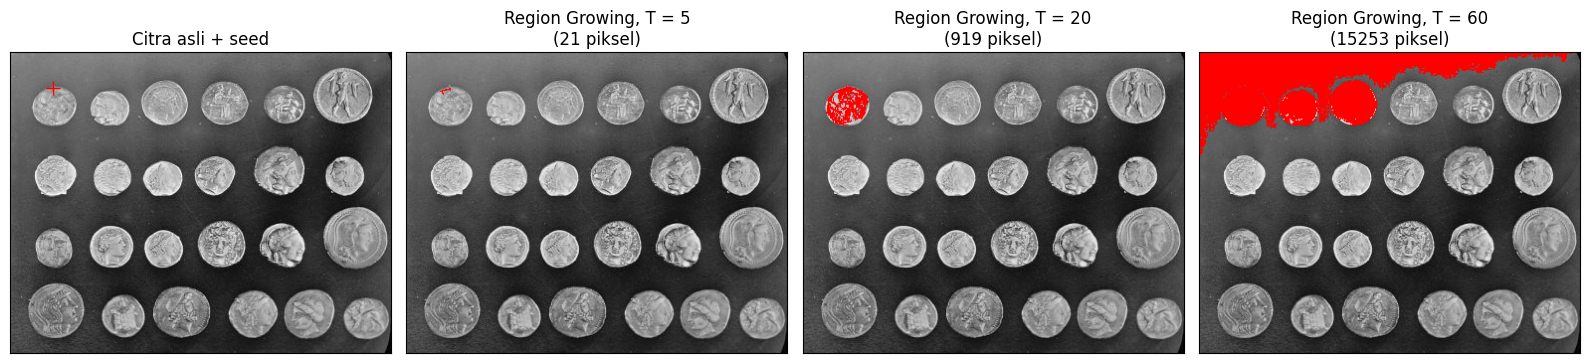

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

# Load citra coins
gray = data.coins()

# Tentukan titik seed dan toleransi sesuai modul
seed = (36, 43)  # (baris, kolom)
seed_val = gray[seed]
tolerances = [5, 20, 60]

# Print header output teks sesuai petunjuk modul
print(f"Seed (baris, kolom): {seed} | intensitas: {seed_val:.6f}")
for T in tolerances:
    mask_temp = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    print(f"Toleransi {T}: {np.sum(mask_temp)} piksel")

# Plot visualisasi 4 gambar menyamping
plt.figure(figsize=(16, 4))

# 1. Citra Asli + Titik Seed
plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=10)
plt.title("Citra asli + seed")
plt.xticks([]), plt.yticks([])

# 2. Hasil Flood untuk Toleransi 5, 20, dan 60
for i, T in enumerate(tolerances):
    # Menggunakan fungsi bawaan skimage.segmentation.flood
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    pixel_count = np.sum(mask)

    # Overlay merah untuk region hasil flood
    overlay = np.stack([gray] * 3, axis=-1)
    overlay[mask] = [255, 0, 0]

    plt.subplot(1, 4, i + 2)
    plt.imshow(overlay)
    plt.title(f"Region Growing, T = {T}\n({pixel_count} piksel)")
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

### NO 7

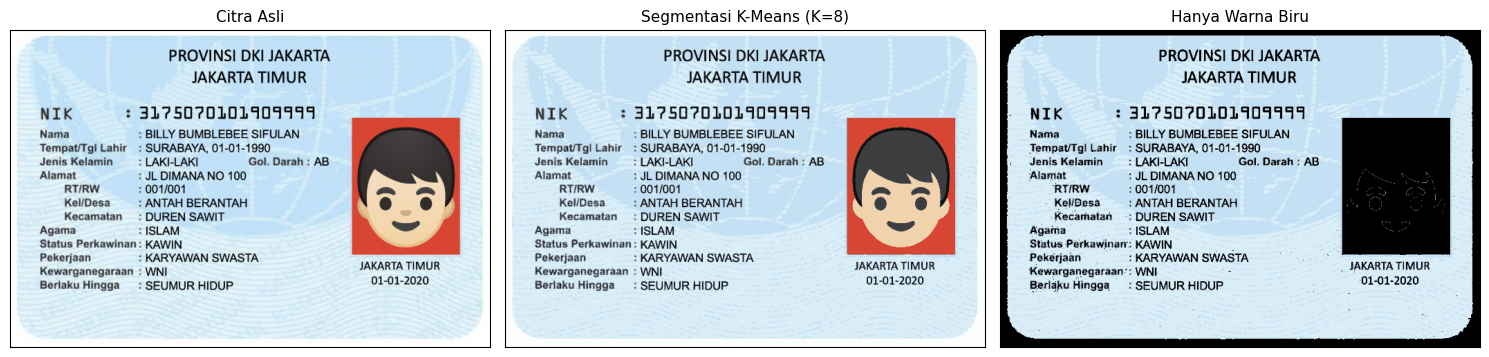

In [ ]:
img_path = '//content/drive/MyDrive/PCVK2026/ktp_fulan.jpg'
img_bgr = cv.imread(img_path)

if img_bgr is None:
    raise FileNotFoundError(f"Gambar tidak ditemukan di path: {img_path}")

img_rgb = cv.cvtColor(img_bgr, cv.COLOR_BGR2RGB)

# Segmentasi K-Means Clustering (K = 8)
# Ubah data citra menjadi matriks piksel 2D (jumlah_piksel, 3 channel)
pixel_values = img_rgb.reshape((-1, 3))
pixel_values = np.float32(pixel_values)

# Definisikan kriteria penghentian K-Means
criteria = (cv.TERM_CRITERIA_EPS + cv.TERM_CRITERIA_MAX_ITER, 100, 0.2)
k = 8
_, labels, centers = cv.kmeans(pixel_values, k, None, criteria, 10, cv.KMEANS_RANDOM_CENTERS)

# Konversi kembali pusat kluster ke uint8
centers = np.uint8(centers)

# Petakan label kembali ke warna pusat kluster
segmented_data = centers[labels.flatten()]
segmented_image = segmented_data.reshape(img_rgb.shape)

# Filtering Warna Biru Menggunakan HSV
# Konversi hasil K-Means ke ruang warna HSV
hsv_image = cv.cvtColor(segmented_image, cv.COLOR_RGB2HSV)
H = hsv_image[:, :, 0]
S = hsv_image[:, :, 1]
V = hsv_image[:, :, 2]

# Rentang kelompok biru sesuai petunjuk di soal: (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)
blue_mask = (H >= 85) & (H <= 130) & (S >= 25) & (V >= 40)

# Buat citra khusus hanya warna biru (piksel luar kelompok_biru diubah menjadi hitam)
only_blue = segmented_image.copy()
only_blue[~blue_mask] = [0, 0, 0]

titles = ['Citra Asli', f'Segmentasi K-Means (K={k})', 'Hanya Warna Biru']
images = [img_rgb, segmented_image, only_blue]

plt.figure(figsize=(15, 5))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i], fontsize=11)
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## D2. Tugas Kelompok

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
import pandas as pd

# Fungsi pemrosesan dasar
def get_ocr_data(img_path):
    img_color = cv.imread(img_path)
    if img_color is None:
        raise FileNotFoundError(f"File tidak ditemukan: {img_path}")

    img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
    img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

    blur = cv.GaussianBlur(img_gray, (5, 5), 0)
    _, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    img_adaptive = cv.adaptiveThreshold(blur, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C, cv.THRESH_BINARY, 11, 2)

    images = {
        'Berwarna': img_rgb,
        'Otsu': cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB),
        'Adaptive': cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB)
    }

    config = '--psm 6'
    lang = 'ind+eng'
    results_text = {}
    conf_summary = {}

    for name, img in images.items():
        data = pytesseract.image_to_data(img, lang=lang, config=config, output_type=Output.DICT)
        text_out = pytesseract.image_to_string(img, lang=lang, config=config)
        results_text[name] = text_out

        conf_list = [float(data['conf'][j]) for j in range(len(data['text'])) if float(data['conf'][j]) > 60 and data['text'][j].strip() != ""]
        conf_summary[name] = np.mean(conf_list) if conf_list else 0.0

    return images, results_text, conf_summary

# 1. Fungsi khusus tampilkan gambar
def plot_gambar_dan_bbox(images, lang='ind+eng', config='--psm 6'):
    # Gambar Asli vs Thresholding
    plt.figure(figsize=(15, 3.5))
    for i, (name, img) in enumerate(images.items()):
        plt.subplot(1, 3, i + 1)
        plt.imshow(img)
        plt.title(f"Citra {name}", fontsize=10)
        plt.xticks([]), plt.yticks([])
    plt.suptitle("Tiga Citra untuk Dibandingkan", fontsize=12, y=1.03)
    plt.tight_layout()
    plt.show()

    # Bounding Box
    plt.figure(figsize=(15, 3.5))
    for i, (name, img) in enumerate(images.items()):
        data = pytesseract.image_to_data(img, lang=lang, config=config, output_type=Output.DICT)
        img_bbox = img.copy()
        for j in range(len(data['text'])):
            if float(data['conf'][j]) > 60 and data['text'][j].strip() != "":
                (x, y, w, h) = (data['left'][j], data['top'][j], data['width'][j], data['height'][j])
                cv.rectangle(img_bbox, (x, y), (x + w, y + h), (0, 255, 0), 2)
        plt.subplot(1, 3, i + 1)
        plt.imshow(img_bbox)
        plt.title(f"Area Teks — {name}", fontsize=10)
        plt.xticks([]), plt.yticks([])
    plt.suptitle("Hasil Pembacaan Teks (Bounding Box)", fontsize=12, y=1.03)
    plt.tight_layout()
    plt.show()

# 2. Fungsi khusus tampilkan teks mentah
def print_teks_ocr(results_text):
    for name in ['Berwarna', 'Otsu', 'Adaptive']:
        print(f"========== {name.upper()} ==========")
        print(results_text[name].strip())
        print()

# 3. Fungsi khusus tampilkan tabel
def show_tabel_ocr(results_text, conf_summary, kata_acuan):
    def check_word(target, full_text):
        words = [w.strip(" .,:-/()").upper() for w in full_text.split()]
        for w in words:
            if target.upper() in w or w in target.upper():
                return target
        return "-"

    data_tabel_10 = []
    skor_cocok = {'Berwarna': 0, 'Otsu': 0, 'Adaptive': 0}

    for idx, target in enumerate(kata_acuan[:10], 1):
        res_b = check_word(target, results_text['Berwarna'])
        res_o = check_word(target, results_text['Otsu'])
        res_a = check_word(target, results_text['Adaptive'])

        if res_b == target: skor_cocok['Berwarna'] += 1
        if res_o == target: skor_cocok['Otsu'] += 1
        if res_a == target: skor_cocok['Adaptive'] += 1

        data_tabel_10.append({
            'No.': idx,
            'Teks Sebenarnya': target,
            'OCR Citra Berwarna': res_b,
            'OCR Otsu': res_o,
            'OCR Adaptive': res_a
        })

    data_ringkasan = []
    for name in ['Berwarna', 'Otsu', 'Adaptive']:
        cocok = skor_cocok[name]
        label = 'Berwarna asli' if name == 'Berwarna' else f'Segmentasi {name}'
        data_ringkasan.append({
            'Citra masukan OCR': label,
            'Item terbaca tepat': cocok,
            'Kecocokan (%)': f"{(cocok/10)*100:.0f}%",
            'Rata-rata confidence': f"{conf_summary[name]:.1f}%"
        })

    print("=== TABEL PERBANDINGAN OCR ===")
    display(pd.DataFrame(data_tabel_10))
    print("\n=== TABEL RINGKASAN KETEPATAN OCR ===")
    display(pd.DataFrame(data_ringkasan))

### KTP Nanta

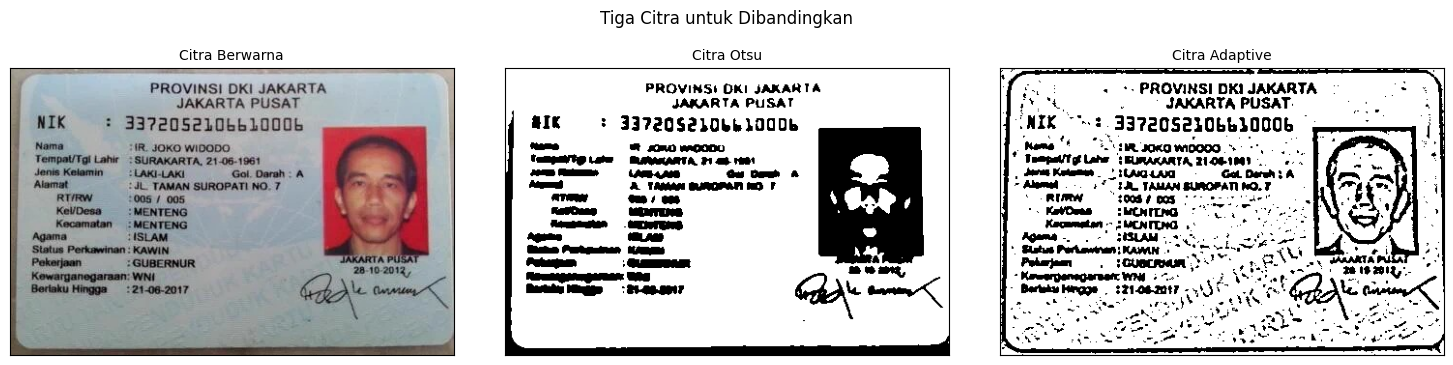

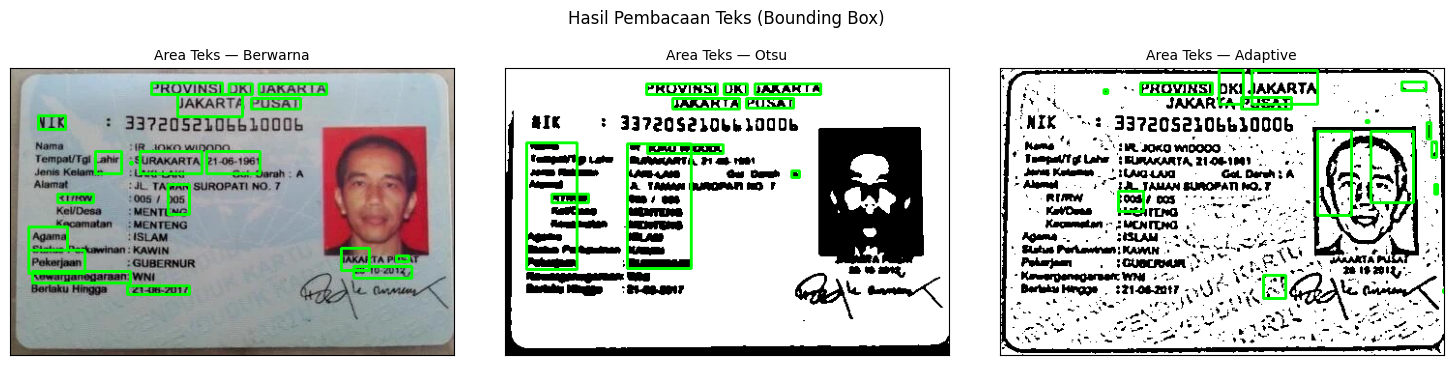

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA PUSAT
NIK + 337205210bb1000b
sana 18 soxo wioo00
Tempat/Tgi Lahir : SURAKARTA. 21-06-1961
Jen Kam AGAN co wr: flem
Kumat AMAN SUROPATLNO.T
RTRW 2005 005 Gak
Kaldena — DMenrena 1
Kecamatan MENTENG
Agama “ISLAM
Pekerjaan Be yan IR TAKA‘ USA
an 28102011,
Kewarganegaraan:
Batak Hinge 21-06-2017 AN cmn

========== OTSU ==========
PROVINS! DKI JAKARTA
JAKARTA PUSAT

are + 337205210bh1000b
= = = EB
TEA Laba BUNMAARTA Hab rot
2... opera Gu Dam A
pont A Taman @UROPAM mT

—. mm

raven no

Mangun tarung
-... ss
eee Pateutan Kamm
Roumpenmgereas: OR omy,
ee "TLP ar sc

========== ADAPTIVE ==========
Kas + +: PROVINSI DKI JAKARTA 2.
ne . JAKARTA PUSAT: eA
-NIK “51. 33720521065 10006 = i
shone OX un yo09 05000 » ¢ 3 :
TnapatiTG Lahu SEURAKARTA HOGI eS
LL Ga Dan
PN TAMAN BUROPATI OT i
KRIM 3008 DOS Fe”. . .

aa Tenaga Era 1g

«Bataan Sie ML AAN:
Pn On TON DO CNC RE “1
+ Kawergenegarsetc MO 1. Ea Say A we
Berak Kenapa . RAIN SAI Kn “at Re cre 

In [ ]:
path_ktp_joko = '/content/drive/MyDrive/PCVK2026/ktp_joko.png'
acuan_ktp_joko = [
    'PROVINSI',
    'JAKARTA',
    'PUSAT',
    'JOKO',
    'WIDODO',
    'SURAKARTA',
    'MENTENG',
    'ISLAM',
    'GUBERNUR',
    'WNI'
]

images, results_text, conf_summary = get_ocr_data(path_ktp_joko)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [ ]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp_joko)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,PUSAT,PUSAT,PUSAT,PUSAT
3,4,JOKO,JOKO,JOKO,JOKO
4,5,WIDODO,WIDODO,WIDODO,WIDODO
5,6,SURAKARTA,SURAKARTA,SURAKARTA,SURAKARTA
6,7,MENTENG,MENTENG,MENTENG,MENTENG
7,8,ISLAM,ISLAM,ISLAM,ISLAM
8,9,GUBERNUR,GUBERNUR,GUBERNUR,GUBERNUR
9,10,WNI,WNI,WNI,WNI



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,86.4%
1,Segmentasi Otsu,10,100%,83.1%
2,Segmentasi Adaptive,10,100%,78.1%


Pertanyaan Analisis (KTP Joko Widodo):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Meskipun ketiga metode pada tabel ringkasan menunjukkan tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki nilai rata-rata confidence paling tinggi yaitu 86.4% (dibanding Otsu 83.1% dan Adaptive 78.1%).

2. Dua Kesalahan Pembacaan
- Kesalahan Karakter Nama & NIK: NIK terbaca salah sebagai 'NIK + 337205210bb1000b' (angka '6' terbaca menjadi huruf 'b'), dan baris Nama terbaca sebagai 'sana 18 soxo wioo00'.
- Karakter Liar akibat Background: Baris Alamat terbaca 'Kumat AMAN SUROPATLNO.T', serta baris Kel/Desa terbaca 'Kaldena — DMENRENA 1'. Pada Adaptive Thresholding, tekstur garis background dan pasfoto menimbulkan banyak bounding box palsu di sekitar gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kata kunci acuan utama tetap dapat dikenali 100%, binarisasi (Otsu dan Adaptive) memotong karakter tipis dan memunculkan noise bintik hitam pada latar belakang, yang menurunkan nilai rata-rata confidence dari 86.4% menjadi 83.1% (Otsu) dan 78.1% (Adaptive).

4. Pengaruh Latar Belakang
Latar belakang bergelombang peta KTP dan gambar pasfoto mengurangi tingkat kontras teks. Pada Adaptive Thresholding, pola latar belakang terkonversi menjadi piksel-piksel hitam rapat yang dianggap sebagai objek oleh Tesseract, sehingga memicu munculnya banyak bounding box palsu di luar area teks.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli memiliki rata-rata confidence tertinggi (86.4%) dan berbanding lurus dengan tingkat kecocokan 100%, serta menghasilkan teks ekstraksi yang paling minim noise binarisasi.

### KTP Aldyth


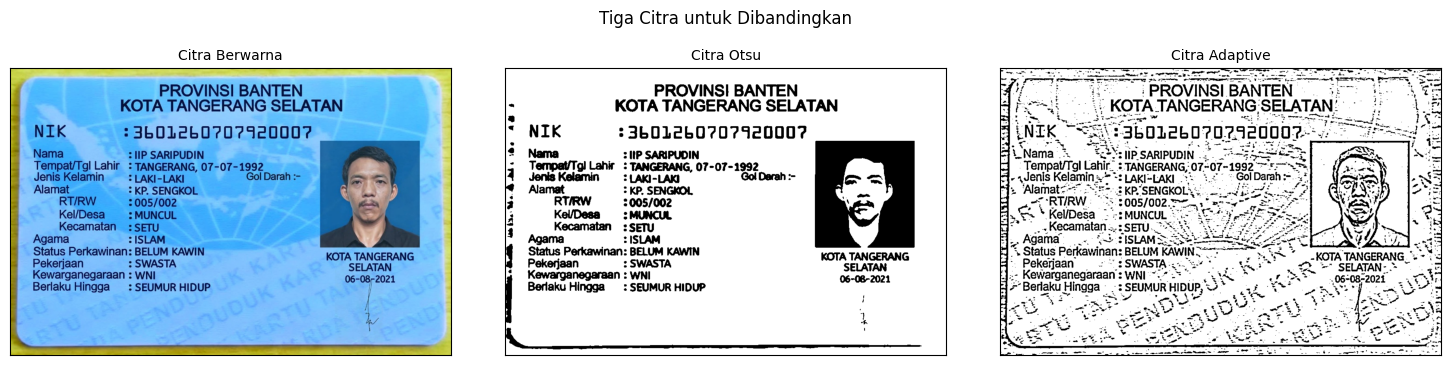

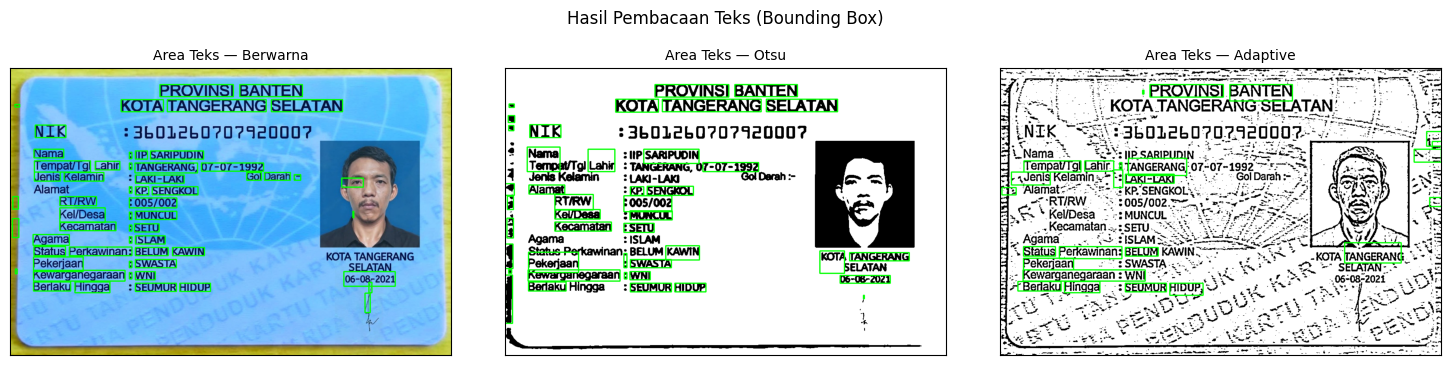

========== BERWARNA ==========
PROVINSI BANTEN
4 KOTA TANGERANG SELATAN
2
" NIK -36012b60707920007
8 Nama 2 IIP SARIPUDIN
_ Tempat/Tgl Lahir : TANGERANG, 07-07-1992
4 Jenis Kelamin = LAKI-LAKI Gol Darah :- i=
*  Alamat : KP. SENGKOL &
- RT/RW :005/002 ag
4 Kel/Desa : MUNCUL |
3 Kecamatan : SETU
Agama : ISLAM
Status Perkawinan: BELUM KAWIN
: Pekerjaan : SWASTA MEN GERAM s
| Kewarganegaraan : WNI 06-08-2021
Berlaku Hingga =: SEUMUR HIDUP ||
|
: WZ
SR ea nan aa SE

========== OTSU ==========
PROVINSI BANTEN

- KOTA TANGERANG SELATAN

a

“ NIK *36012bL0707920007

ba Nama Lahir pli SARIPUDIN 7-07-1992

| Tempat Lahir Fancenans,o7-or-s997 an. Mifl

€ Alamat : KP. SENGKOL PX

3 RTRW 2005/002 V

P Kel/Desa = : MUNCUL

3 Kecamatan :SETU

Status Perkawinan BELUM KAWIN

| Pekerjaan 1 SWASTA KOTA TANGERANG

4 Kewarganegaraan : WNI 06-08-2021

| Berlaku Hingga =: SEUMUR HIDUP |
4

========== ADAPTIVE ==========
Sh ia aa en Pan Panen PAI, Ea
4 Pp : PROVINSI BANTEN pS te AT
HS ay KOTA-TANGERANG ‘SELA

In [ ]:
path_ktp = '/content/drive/MyDrive/PCVK2026/ktp_iip.jpg'
acuan = [
    'PROVINSI',
    'BANTEN',
    'TANGERANG',
    'SARIPUDIN',
    'SENGKOL',
    'MUNCUL',
    'SETU',
    'ISLAM',
    'SWASTA',
    'SEUMUR'
]

images, results_text, conf_summary = get_ocr_data(path_ktp)

# Tampilan Gambar Asli vs Thresholding & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Hasil Pembacaan Teks Mentah
print_teks_ocr(results_text)

In [ ]:
# Tampilan tabel perbandingan 10 kata acuan & ringkasan akurasi
show_tabel_ocr(results_text, conf_summary, acuan)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,BANTEN,BANTEN,BANTEN,BANTEN
2,3,TANGERANG,TANGERANG,TANGERANG,TANGERANG
3,4,SARIPUDIN,SARIPUDIN,SARIPUDIN,SARIPUDIN
4,5,SENGKOL,SENGKOL,SENGKOL,SENGKOL
5,6,MUNCUL,MUNCUL,MUNCUL,MUNCUL
6,7,SETU,SETU,SETU,SETU
7,8,ISLAM,ISLAM,ISLAM,ISLAM
8,9,SWASTA,SWASTA,SWASTA,SWASTA
9,10,SEUMUR,SEUMUR,SEUMUR,SEUMUR



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,89.1%
1,Segmentasi Otsu,10,100%,86.9%
2,Segmentasi Adaptive,10,100%,82.4%


Pertanyaan Analisis (KTP Iip Saripudin):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Walaupun ketiga citra memiliki tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi yaitu 89.1% (dibanding Otsu 86.9% dan Adaptive 82.4%).

2. Dua Kesalahan Pembacaan
- Karakter Karcis/Noise Latar: Pada citra Berwarna Asli, angka NIK terbaca salah sebagai '" NIK -36012b60707920007' (huruf 'b' menyisip di tengah angka).
- Bintik Noise Tepi: Pada citra Adaptive, garis-garis watermark background KTP terkonversi menjadi piksel hitam rapat sehingga memunculkan karakter acak seperti 'WZ' dan 'SR ea nan aa' di bagian bawah.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan performa OCR. Pada sampel ini, kecocokan kata kunci memang tetap 100%, namun proses binarisasi (Otsu dan Adaptive) justru menurunkan nilai confidence dari 89.1% menjadi 86.9% dan 82.4% karena memunculkan noise di area batas huruf dan gambar pasfoto.

4. Pengaruh Latar Belakang
Pola garis-garis pengaman dan watermark pada KTP mengurangi kontras. Pada Adaptive Thresholding, pola latar belakang terikut sebagai garis hitam yang dinilai sebagai objek oleh Tesseract, sehingga memunculkan banyak bounding box palsu di luar area teks utama.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli yang memiliki rata-rata confidence tertinggi (89.1%) terbukti menghasilkan pembacaan yang paling bersih dari noise tambahan, berbanding lurus dengan kecocokan sempurna 100%.

### KTP Nawfal

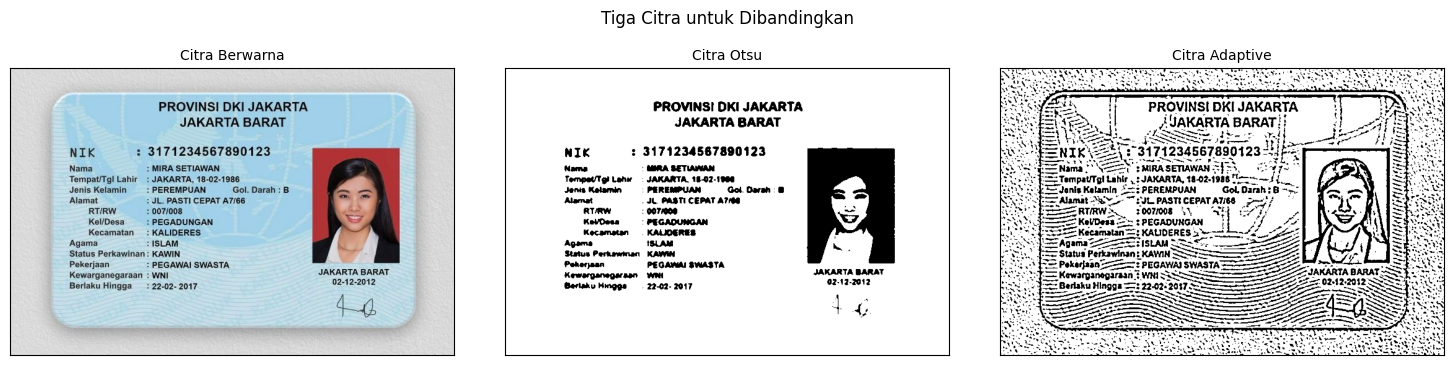

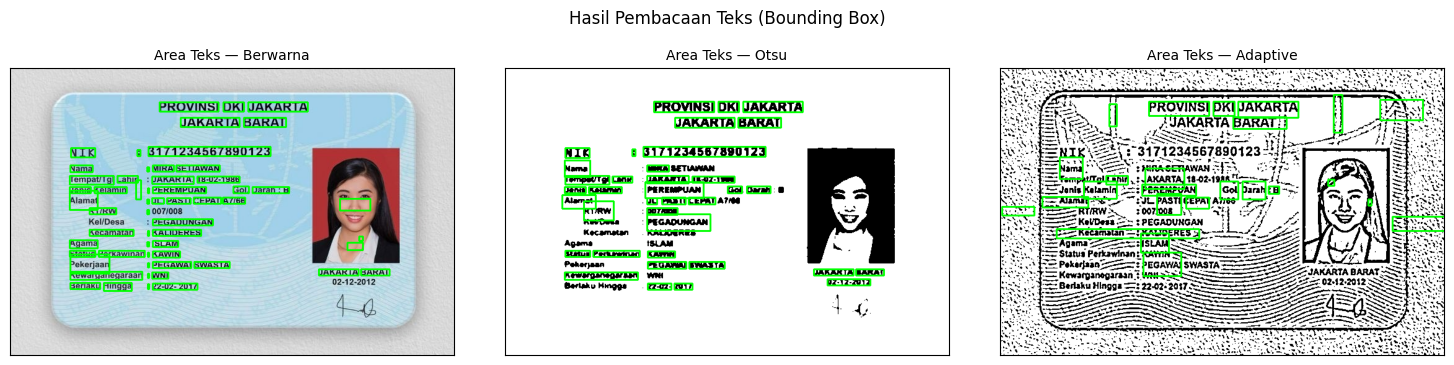

========== BERWARNA ==========
PROVINSI DKI JAKARTA
JAKARTA BARAT
NIK : 3171234567890123
Nama : MIRA SETIAWAN
Tempat/Tgl Lahir  : JAKARTA, 18-02-1986
Jenis Kelamin — : PEREMPUAN —_ Gol. Darah:B -_
Alamat : JL. PASTI CEPAT A7/66 wlw
RTIRW : oo7/oog =
KellDesa — : PEGADUNGAN -
Kecamatan : KALIDERES 4
Agama : ISLAM wh
Status Perkawinan : KAWIN O
Pekerjaan : PEGAWAI SWASTA
Kewarganegaraan : WNI JAKARTA BARAT.
Berlaku Hingga — : 22-02-2017 EEE

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA BARAT
NIK : 3171234567890123
Nama WA SETAN
Tempet/Tgi Lahir: JAKARTA, 18-07-1968
Jenis Kelamin PEREMPUAN Gol. Darah 8
Alamat JL. PASTI CEPAT A70
RTRW 077000
Kelasa PEGADUNGAN Ss
Kecamatan. KALOERES
. jera Ne
Status Perkawinan KAWIN .
Peherjaan PEGAWAI SWASTA
Kewarganegaraan WNI JAKARTA BARAT
Bertaku Hingga. 22-02- 2017 02-12-2012
14

========== ADAPTIVE ==========
EA NA AAA DRA RESES RENA
NA aa Kana : $ Sen Sa Kan
CO aa ana PAN PNP KAPAN MANA
US ‘Gon ‘| PROVINSI DKI JAKARTA H PAN Be
EEE, i ASAKA

In [ ]:
path_ktp3 = '/content/drive/MyDrive/PCVK2026/ktp_mira.jpg'
acuan_ktp3 = [
    'PROVINSI',
    'JAKARTA',
    'BARAT',
    'MIRA',
    'SETIAWAN',
    'PEREMPUAN',
    'PEGADUNGAN',
    'KALIDERES',
    'ISLAM',
    'KAWIN'
]

images, results_text, conf_summary = get_ocr_data(path_ktp3)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [ ]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp3)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,BARAT,BARAT,BARAT,BARAT
3,4,MIRA,MIRA,MIRA,MIRA
4,5,SETIAWAN,SETIAWAN,SETIAWAN,SETIAWAN
5,6,PEREMPUAN,PEREMPUAN,PEREMPUAN,PEREMPUAN
6,7,PEGADUNGAN,PEGADUNGAN,PEGADUNGAN,PEGADUNGAN
7,8,KALIDERES,KALIDERES,KALIDERES,KALIDERES
8,9,ISLAM,ISLAM,ISLAM,ISLAM
9,10,KAWIN,KAWIN,KAWIN,KAWIN



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,86.2%
1,Segmentasi Otsu,10,100%,83.8%
2,Segmentasi Adaptive,10,100%,79.0%


Pertanyaan Analisis (KTP Mira Setiawan):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Meskipun ketiga metode sama-sama menghasilkan tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki rata-rata confidence paling tinggi yaitu 86.2% (dibanding Otsu 83.8% dan Adaptive 79.0%).

2. Dua Kesalahan Pembacaan
- Kesalahan Karakter Angka & Simbol: Angka RT/RW '007/008' terbaca salah sebagai 'oo7/oog =' pada hasil ekstraksi teks.
- Karakter Liar/Noise Tambahan: Pembacaan alamat menambahkan teks acak di akhir menjadi 'A7/66 wlw', serta kata 'KAWIN' terbaca 'KAWIN O'. Pada hasil Adaptive Thresholding, pola background KTP menghasilkan banyak bounding box palsu di tepi gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kecocokan kata kunci acuan mencapai 100% pada semua metode, proses segmentasi (Otsu dan Adaptive) justru menurunkan nilai rata-rata confidence secara berturut-turut dari 86.2% menjadi 83.8% dan 79.0% karena binarisasi memunculkan noise garis/bintik pada latar belakang.

4. Pengaruh Latar Belakang
Pola garis-garis peta dan watermark pada background KTP memunculkan noise saat binarisasi. Pada Adaptive Thresholding, tekstur background terkonversi menjadi garis-garis hitam yang dikira karakter teks oleh Tesseract, sehingga mendeteksi banyak area palsu di luar teks utama.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi (86.2%) sekaligus tingkat kecocokan 100%, yang menunjukkan bahwa semakin tinggi tingkat kejelasan citra tanpa noise binarisasi, semakin tinggi pula skor kepercayaan yang diberikan oleh Tesseract.

### KTP Vanesa

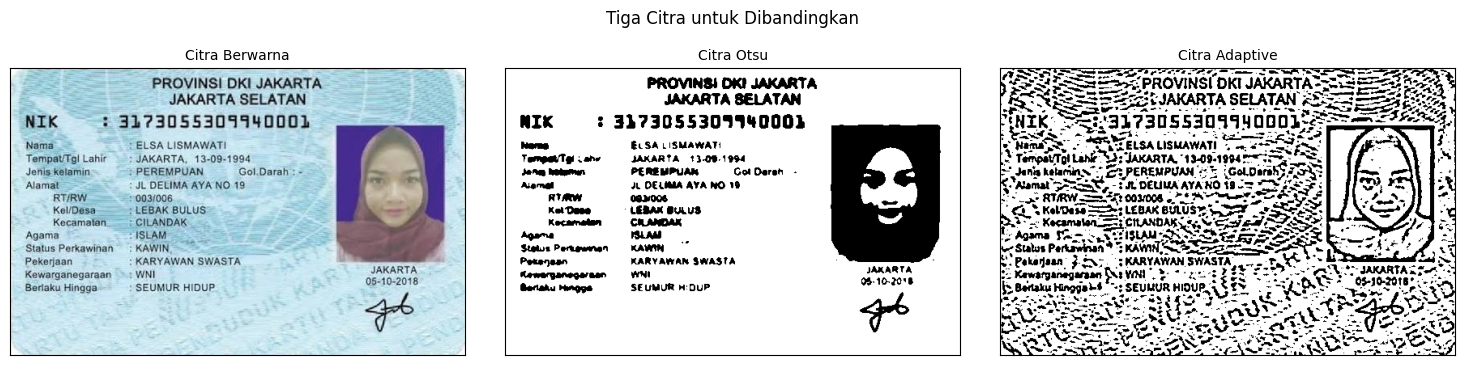

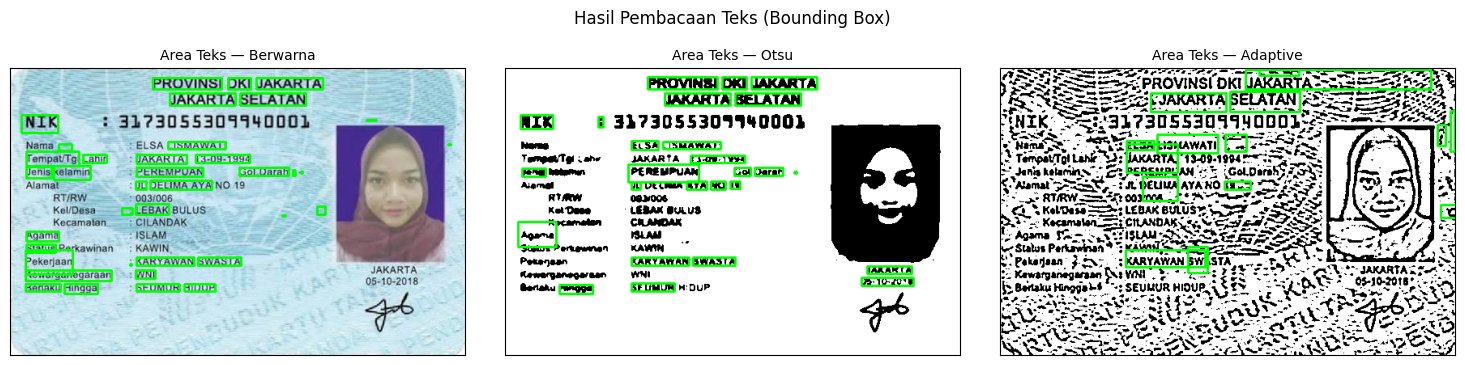

========== BERWARNA ==========
Da PROVINSI DKI JAKARTA =e Se
= JAKARTA SELATAN Sz
NIK 2 3193055309940001 = ee
Nama — —— GELSA LISMAWATI F
Tempat/Tgl Lahir - : JAKARTA, 13-09-1994
Jenis Kelamin. : PEREMPUAN Gol.Darah : = |
Alamat 55: JL DELIMAAYA NO 19

RTIRW = =: 003/006

Kel/Desa—— —: LEBAK BULUS 3 =

Kecamatan... :CILANDAK..
Agama Sie SS SS
Status Perkawinan: KAWIN,
Pekerjaan : KARYAWAN SWASTA -.
Kewarganegaraan ~ : WNI Na
Berlaku Hingga SEUMUR HIDUP

========== OTSU ==========
PROVINSI DKI JAKARTA
JAKARTA SELATAN
NIK 2 337305530994000)
wang ELSA LISMAWAT!
TEMPALTA Lahu JAKARTA 13-08-1994
Jang beter PEREMPUAK Got Darah -
ara JL DELMMA AYA NO 19
aa 09006
Ker Dace LEBAK Buus
Kecamatan CILANDAK
Agama MM.
‘Stetus Pertewnen KAWIN
Poranean KARYAWAN SWASTA
« JAKARTA
en wt 08-10-2016
Merahu rangga SEUMUR W:DUP

========== ADAPTIVE ==========
ASC PE PROVING DIT JAKARTA nan ih.
FS SSE ROVINSI DKI JAKARTA sees Beas tet 8
BSS ESS PE JAKARTA SELATAN FEE
ik SEA 7ans saa a qwoOOR ees
& Maman cet EL

In [ ]:
path_ktp4 = '/content/drive/MyDrive/PCVK2026/ktp_elsa.jpg'
acuan_ktp4 = [
    'PROVINSI',
    'JAKARTA',
    'SELATAN',
    'ELSA',
    'LISMAWATI',
    'PEREMPUAN',
    'DELIMA',
    'LEBAK',
    'CILANDAK',
    'ISLAM'
]

images, results_text, conf_summary = get_ocr_data(path_ktp4)

# Tampilan Gambar & Bounding Box
plot_gambar_dan_bbox(images)

# Tampilan Teks Mentah Hasil OCR
print_teks_ocr(results_text)

In [ ]:
show_tabel_ocr(results_text, conf_summary, acuan_ktp4)

=== TABEL PERBANDINGAN OCR ===


,No.,Teks Sebenarnya,OCR Citra Berwarna,OCR Otsu,OCR Adaptive
0,1,PROVINSI,PROVINSI,PROVINSI,PROVINSI
1,2,JAKARTA,JAKARTA,JAKARTA,JAKARTA
2,3,SELATAN,SELATAN,SELATAN,SELATAN
3,4,ELSA,ELSA,ELSA,ELSA
4,5,LISMAWATI,LISMAWATI,LISMAWATI,LISMAWATI
5,6,PEREMPUAN,PEREMPUAN,PEREMPUAN,PEREMPUAN
6,7,DELIMA,DELIMA,DELIMA,DELIMA
7,8,LEBAK,LEBAK,LEBAK,LEBAK
8,9,CILANDAK,CILANDAK,CILANDAK,CILANDAK
9,10,ISLAM,ISLAM,ISLAM,ISLAM



=== TABEL RINGKASAN KETEPATAN OCR ===


,Citra masukan OCR,Item terbaca tepat,Kecocokan (%),Rata-rata confidence
0,Berwarna asli,10,100%,87.6%
1,Segmentasi Otsu,10,100%,80.1%
2,Segmentasi Adaptive,10,100%,77.4%


Pertanyaan Analisis (KTP Elsa Lismawati):

1. Citra Masukan Paling Tepat
Citra Berwarna Asli. Meskipun ketiga metode pada tabel ringkasan menunjukkan tingkat kecocokan 100% (10 dari 10 item terbaca tepat), citra Berwarna Asli memiliki nilai rata-rata confidence tertinggi yaitu 87.6% (dibanding Otsu 80.1% dan Adaptive 77.4%).

2. Dua Kesalahan Pembacaan
- Kesalahan Karakter Nama & NIK: Nama 'ELSA LISMAWATI' terbaca salah sebagai 'GELSA LISMAWATI F', dan NIK terbaca menyisip angka liar menjadi 'NIK 2 3193055309940001'.
- Karakter Liar akibat Background: Pada bagian Agama terbaca 'Agama Sie SS SS' dan Alamat terbaca 'Alamat 55: JL DELIMAAYA NO 19'. Pada Adaptive Thresholding, tekstur background KTP menimbulkan banyak bounding box palsu di sekitar gambar.

3. Pengaruh Segmentasi terhadap Ketepatan OCR
Segmentasi tidak selalu meningkatkan ketepatan OCR. Meskipun kata kunci acuan tetap terdeteksi 100%, binarisasi (Otsu dan Adaptive) memotong karakter tipis dan memunculkan noise bintik hitam, sehingga menurunkan nilai confidence dari 87.6% menjadi 80.1% (Otsu) dan 77.4% (Adaptive).

4. Pengaruh Latar Belakang
Latar belakang bergelombang dan gambar pasfoto pada KTP mengurangi kontras teks. Pada Adaptive Thresholding, pola latar belakang terkonversi menjadi piksel-piksel hitam rapat yang dianggap sebagai objek oleh Tesseract, memicu munculnya banyak bounding box palsu.

5. Hubungan Confidence dan Kecocokan
Ya. Citra Berwarna Asli memiliki rata-rata confidence tertinggi (87.6%) dan berbanding lurus dengan tingkat kecocokan 100%, serta menghasilkan teks ekstraksi yang paling minim noise binarisasi.